<a href="https://colab.research.google.com/github/nicolastibata/MINE_4210_ADL_202620/blob/main/lab/Laboratorio_9/MINE_4210_ADL_202620_L9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Logo ADL](https://github.com/nicolastibata/MINE_4210_ADL_202620/blob/main/docs/logo.png?raw=true)

# **Laboratorio 9: VIT Models for computer vision**
**Tutor: Nicolás Tibatá**

## **Tabla de Contenido**

[Contexto y objetivos](#scrollTo=R4YrUaE6udsU&line=14&uniqifier=1)<br>
[1. Comprensión de los datos](#scrollTo=VjA8zwzJvmeO&line=1&uniqifier=1)<br>
[2. Preparación de los datos](#scrollTo=kG8XHROzvuEH&line=1&uniqifier=1)<br>
[3. Modelamiento](#scrollTo=wCS6xYiU4YYs&line=1&uniqifier=1)<br>
[4. Evaluación](#scrollTo=nnCc67Uf5urd&line=1&uniqifier=1)<br>
[5. Detección, segmentación y modelos generativos](#scrollTo=52G-zC-3DTEj&line=1&uniqifier=1)<br>
[6. Preguntas](#scrollTo=8Z94PZwqmXeI&line=1&uniqifier=1)<br>

### **Contexto y Objetivos**

**Problema**
- Una empresa de gestión de residuos quiere automatizar la clasificación de residuos domésticos a partir de fotografías (batería, vidrio, plástico, etc.) para apoyar la separación en la fuente. Antes de invertir en entrenar modelos propios, quiere saber qué tan bien funcionan los Transformers de visión preentrenados y qué más pueden hacer (detectar y segmentar objetos).

**Objetivos**
1. Entender cómo un Vision Transformer (ViT) convierte una imagen en una secuencia de tokens y usarlo para clasificar, comparándolo con una arquitectura convolucional (ResNet).
2. Explorar modelos de detección y segmentación basados en Transformers.



**Datos**

Usaremos el dataset *Garbage Classification V2* (10 clases de residuos domésticos), que puedes consultar [aquí](https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2). Para mantener el costo bajo trabajaremos con una submuestra del dataset.

*Disclaimer: en el Laboratorio 8 usamos un *decoder* (GPT) con prompting. Ahora llevamos la misma arquitectura Transformer a las **imágenes**: donde nuestros "tokens" serán *parches* de imagen.*

In [ ]:
!pip install transformers accelerate timm kaggle -q

In [ ]:
import os
import glob
import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
from scipy.stats import multivariate_normal

from transformers import AutoImageProcessor, AutoModel, pipeline

from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from google.colab import userdata

In [ ]:
# Definimos nuestras semillas de reproducibilidad
SEED = 71
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)


Dispositivo: cuda


### **1. Comprensión de los datos**

Para entender cómo traemos los datos desde kaggle pueden revisar este [link](https://www.kaggle.com/discussions/general/51898#520673)

In [ ]:
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')

!kaggle datasets download -d sumn2u/garbage-classification-v2

! unzip -q -o "garbage-classification-v2.zip" -d /content/garbage

Dataset URL: https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2
License(s): MIT
100% 1.07G/1.07G [00:12<00:00, 93.6MB/s]



In [ ]:
# Recorremos las carpetas: la etiqueta de cada imagen es el nombre de su carpeta
CLASES = ['battery', 'biological', 'cardboard', 'clothes', 'glass',
          'metal', 'paper', 'plastic', 'shoes', 'trash']
EXTENSIONES = ('.jpg', '.jpeg', '.png')

Total de imágenes: 36777
Clases encontradas: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']


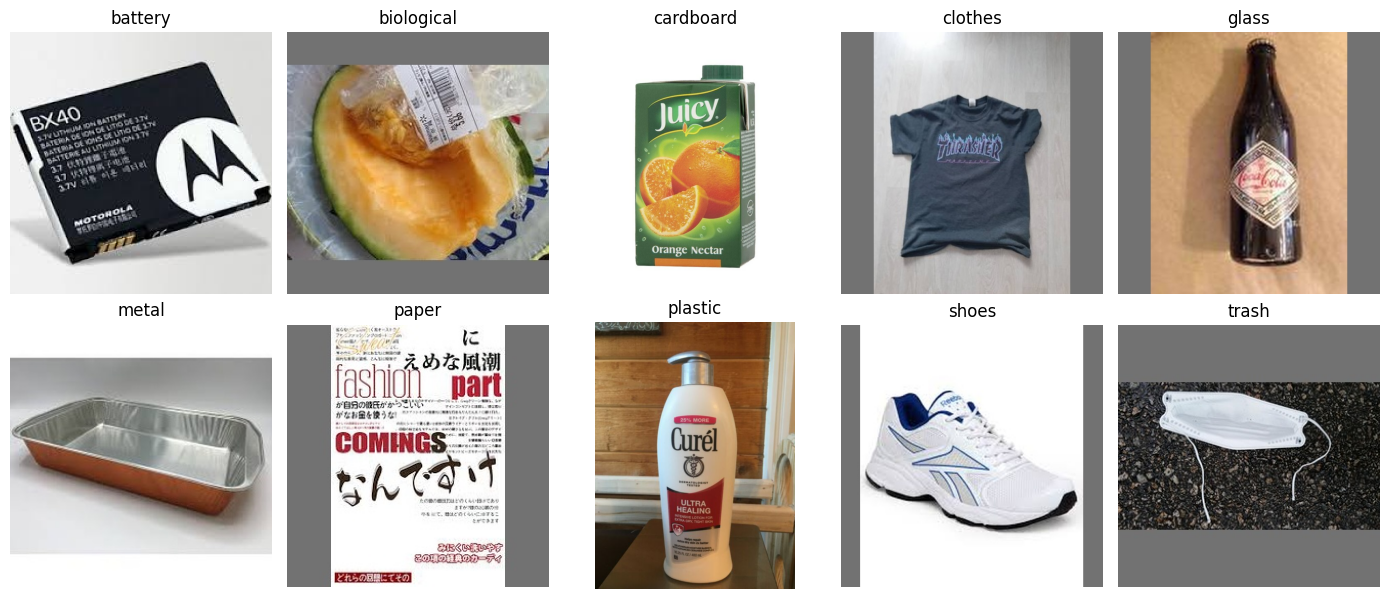

Ancho: min=168, mediana=384, max=2048
Alto : min=91, mediana=384, max=1920


In [ ]:
rutas = [p for p in glob.glob('/content/garbage/**/*', recursive=True) if p.lower().endswith(EXTENSIONES)]
df = pd.DataFrame({'path': rutas})
df['label'] = df['path'].apply(lambda p: os.path.basename(os.path.dirname(p)).lower())
df = df[df['label'].isin(CLASES)].reset_index(drop=True)

print("Total de imágenes:", len(df))
print("Clases encontradas:", sorted(df['label'].unique()))
df['label'].value_counts()

# Veamos una imagen por clase
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, clase in zip(axes.ravel(), CLASES):
    ruta = df[df['label'] == clase]['path'].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(ruta).convert('RGB'))
    ax.set_title(clase)
    ax.axis('off')
plt.tight_layout()
plt.show()

# y veamos los tamaños
tamanos = [Image.open(p).size for p in df['path'].sample(300, random_state=SEED)]
anchos, altos = zip(*tamanos)
print(f"Ancho: min={min(anchos)}, mediana={int(np.median(anchos))}, max={max(anchos)}")
print(f"Alto : min={min(altos)}, mediana={int(np.median(altos))}, max={max(altos)}")


> Como vemos las imágenes tienen tamaños distintos, los modelos de visión esperan una entrada fija (224×224 en nuestro caso). Por lo tanto usamos el *image processor* de nuestro modelo para que se encargue de redimensionar y normalizar.


### **2. Preparación de los datos**

Para controlar el costo tomamos una **submuestra balanceada** de 120 imágenes por clase y hacemos la misma partición de los laboratorios anteriores: prueba (20%), validación (20% del resto) y entrenamiento.

In [ ]:
N_POR_CLASE = 120
n = min(N_POR_CLASE, df['label'].value_counts().min())
df_sub = df.groupby('label').sample(n=n, random_state=SEED).reset_index(drop=True)

In [ ]:
# Codificamos las etiquetas
label_encoder = LabelEncoder()
df_sub['y'] = label_encoder.fit_transform(df_sub['label'])
classes_names = [str(c) for c in label_encoder.classes_]
for valor_numerico, etiqueta_original in enumerate(classes_names):
    print(f'Valor numérico: {valor_numerico}, Etiqueta original: {etiqueta_original}')

train, test = train_test_split(df_sub, test_size=0.2, stratify=df_sub['y'], random_state=42, shuffle=True)
train, val = train_test_split(train, test_size=0.2, stratify=train['y'], random_state=42, shuffle=True)
train, val, test = train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

print("Tamaño de datos de entrenamiento:", train.shape)
print("Tamaño de datos de validación:", val.shape)
print("Tamaño de datos de prueba:", test.shape)

Valor numérico: 0, Etiqueta original: battery
Valor numérico: 1, Etiqueta original: biological
Valor numérico: 2, Etiqueta original: cardboard
Valor numérico: 3, Etiqueta original: clothes
Valor numérico: 4, Etiqueta original: glass
Valor numérico: 5, Etiqueta original: metal
Valor numérico: 6, Etiqueta original: paper
Valor numérico: 7, Etiqueta original: plastic
Valor numérico: 8, Etiqueta original: shoes
Valor numérico: 9, Etiqueta original: trash
Tamaño de datos de entrenamiento: (768, 3)
Tamaño de datos de validación: (192, 3)
Tamaño de datos de prueba: (240, 3)


In [ ]:
y_train, y_val, y_test = train['y'].values, val['y'].values, test['y'].values

### **3. Modelamiento**

#### **3.1. Arquitectura de un vision transformer**

Un ViT no procesa píxeles uno a uno, sino que procesa por parches. Convierte cada parche en un vector y trata la secuencia de parches como si fueran las palabras de una frase. Se antepone un token especial `[CLS]`, igual que en BERT, cuyo vector final resume la imagen.

Usaremos `google/vit-base-patch16-224-in21k`, preentrenado en ImageNet-21k y sin cabeza de clasificación (solo el encoder).


In [ ]:
VIT_NAME = "google/vit-base-patch16-224-in21k"
proc_vit = AutoImageProcessor.from_pretrained(VIT_NAME)
vit = AutoModel.from_pretrained(VIT_NAME, attn_implementation="eager").to(device).eval()

cfg = vit.config
n_parches = (cfg.image_size // cfg.patch_size) ** 2
print(f"Imagen {cfg.image_size}x{cfg.image_size}, parche {cfg.patch_size}x{cfg.patch_size}")
print(f"Parches por imagen: {n_parches}  ->  secuencia de {n_parches + 1} tokens (con [CLS])")
print(f"Capas: {cfg.num_hidden_layers}, cabezas por capa: {cfg.num_attention_heads}, dimensión: {cfg.hidden_size}")
print(f"Parámetros de ViT-base: {sum(p.numel() for p in vit.parameters())/1e6:.0f}M")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Imagen 224x224, parche 16x16
Parches por imagen: 196  ->  secuencia de 197 tokens (con [CLS])
Capas: 12, cabezas por capa: 12, dimensión: 768
Parámetros de ViT-base: 86M


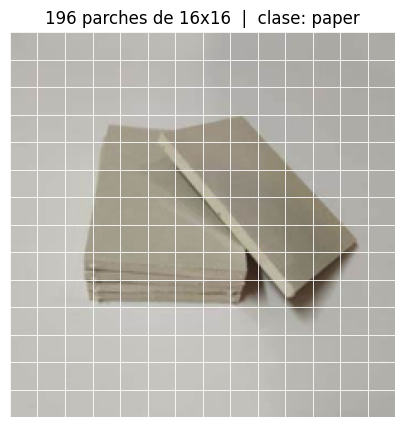

In [ ]:
# Visualicemos cómo "ve" el modelo la imagen
ruta_demo = test['path'].iloc[0]
img_demo = Image.open(ruta_demo).convert('RGB').resize((224, 224))

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img_demo)
for k in range(0, 224 + 1, cfg.patch_size):
    ax.axhline(k - 0.5, color='white', lw=0.6)
    ax.axvline(k - 0.5, color='white', lw=0.6)
ax.set_title(f"{n_parches} parches de {cfg.patch_size}x{cfg.patch_size}  |  clase: {test['label'].iloc[0]}")
ax.axis('off')
plt.show()

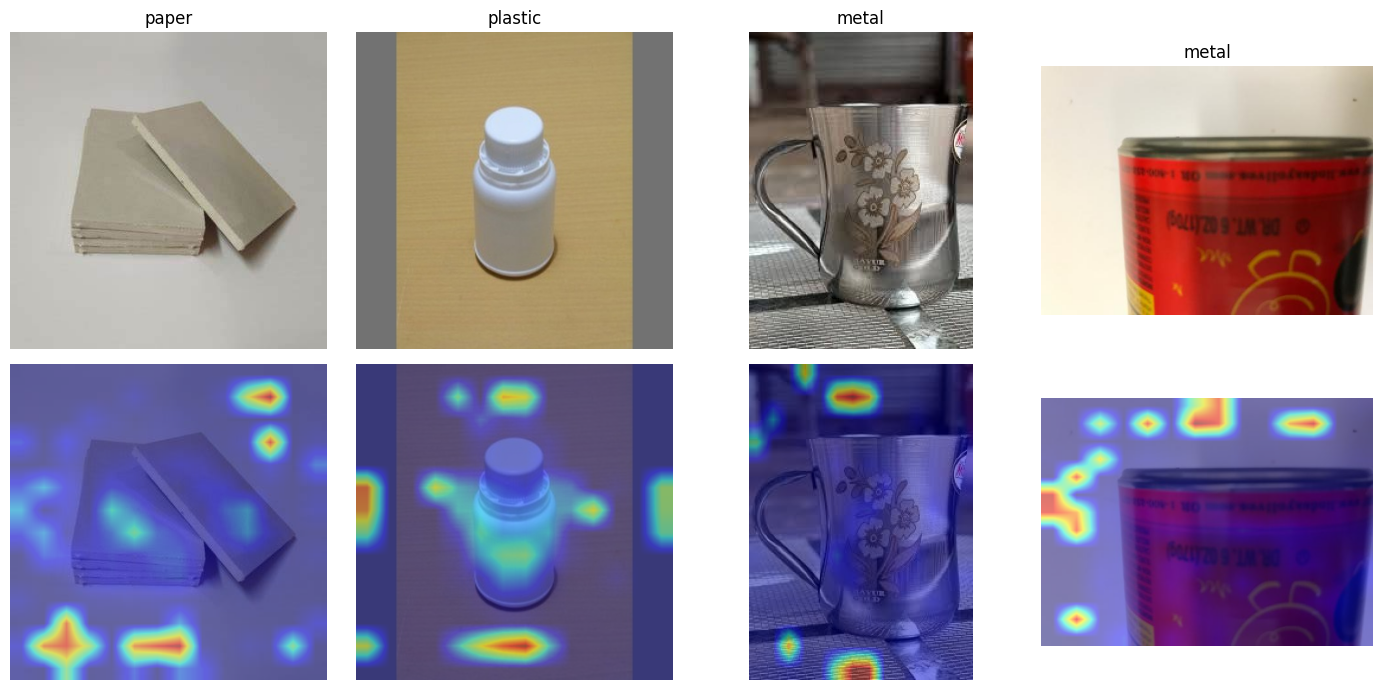

In [ ]:
# Mapa de atención del token [CLS] hacia los parches (promedio de las cabezas de atención)
def mapa_atencion_vit(ruta):
    img = Image.open(ruta).convert('RGB')
    x = proc_vit(images=img, return_tensors='pt').to(device)
    with torch.no_grad():
        out = vit(**x, output_attentions=True)
    att = out.attentions[-1][0].mean(0)          # (tokens, tokens)
    lado = int(np.sqrt(att.shape[-1] - 1))       # 14
    cls_a = att[0, 1:].reshape(lado, lado).cpu().numpy()
    cls_a = (cls_a - cls_a.min()) / (cls_a.max() - cls_a.min() + 1e-9)
    mapa = np.array(Image.fromarray((cls_a * 255).astype(np.uint8)).resize(img.size, Image.BILINEAR)) / 255
    return img, mapa

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    img, mapa = mapa_atencion_vit(test['path'].iloc[i])
    axes[0, i].imshow(img); axes[0, i].set_title(test['label'].iloc[i]); axes[0, i].axis('off')
    axes[1, i].imshow(img); axes[1, i].imshow(mapa, cmap='jet', alpha=0.5); axes[1, i].axis('off')
plt.tight_layout()
plt.show()

> Igual que en el Laboratorio 7 con BertViz, el mapa muestra **a dónde mira** el modelo, no necesariamente **por qué** decide. No hay una relación causal.

> La atención es global desde la primera capa: cualquier parche puede relacionarse con cualquier otro. Una CNN, en cambio, empieza mirando vecindarios locales y va ampliando su campo receptivo capa a capa. Cuál creen que es mejor?

#### **3.2 Clasificación: ViT vs. CNN como extractores de características**

Para que no nos cueste tanto computacionalmente **no entrenamos los modelos**: los usamos congelados como extractores de características (embeddings) y entrenamos solo una regresión logística encima. Comparamos dos arquitecturas con el mismo protocolo:
- **ViT-base** (Transformer): usamos el vector del token `[CLS]`.
- **ResNet-50** (CNN): usamos el vector tras el *global average pooling*.


In [ ]:
@torch.no_grad()
def extraer_embeddings(proc, model, rutas, es_vit, batch_size=32):
    feats = []
    for i in range(0, len(rutas), batch_size):
        imgs = [Image.open(p).convert('RGB') for p in rutas[i:i + batch_size]]
        x = proc(images=imgs, return_tensors='pt').to(device)
        out = model(**x)
        f = out.last_hidden_state[:, 0] if es_vit else out.pooler_output.flatten(1)
        feats.append(f.cpu().numpy())
    return np.vstack(feats)

RESNET_NAME = "microsoft/resnet-50"
proc_rn = AutoImageProcessor.from_pretrained(RESNET_NAME)
resnet = AutoModel.from_pretrained(RESNET_NAME).to(device).eval()

emb, tiempos = {}, {}
for nombre, proc, modelo, es_vit in [("ViT-base", proc_vit, vit, True), ("ResNet-50", proc_rn, resnet, False)]:
    t0 = time.time()
    emb[nombre] = {split: extraer_embeddings(proc, modelo, df_[ 'path'].tolist(), es_vit)
                   for split, df_ in [("train", train), ("val", val), ("test", test)]}
    tiempos[nombre] = time.time() - t0
    print(f"{nombre}: embeddings de dimensión {emb[nombre]['train'].shape[1]} en {tiempos[nombre]:.0f} s")

n_params = {"ViT-base": sum(p.numel() for p in vit.parameters()),
            "ResNet-50": sum(p.numel() for p in resnet.parameters())}

# Entrenamos una regresión logística sobre cada tipo de embedding, eligiendo C con validación
def entrenar_lr(Xtr, ytr, Xva, yva, Cs=(0.01, 0.1, 1, 10)):
    scaler = StandardScaler().fit(Xtr)
    mejor = (-1, None, None)
    for C in Cs:
        clf = LogisticRegression(C=C, max_iter=2000).fit(scaler.transform(Xtr), ytr)
        acc = clf.score(scaler.transform(Xva), yva)
        if acc > mejor[0]:
            mejor = (acc, C, clf)
    print(f"  mejor C={mejor[1]} (accuracy en validación: {mejor[0]:.3f})")
    return scaler, mejor[2]

modelos_lr = {}
for nombre in emb:
    print(nombre)
    modelos_lr[nombre] = entrenar_lr(emb[nombre]['train'], y_train, emb[nombre]['val'], y_val)

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ViT-base: embeddings de dimensión 768 en 21 s
ResNet-50: embeddings de dimensión 2048 en 11 s
ViT-base
  mejor C=0.01 (accuracy en validación: 0.917)
ResNet-50
  mejor C=0.1 (accuracy en validación: 0.911)


### **4. Evaluación**

Evaluamos en el conjunto de prueba. Como las clases están balanceadas, además de accuracy y macro-F1 reportamos el **recall de la peor clase** (la que más se le dificulta al modelo).

In [ ]:
def evaluar(nombre, y_true, y_pred):
    recalls = recall_score(y_true, y_pred, labels=list(range(len(classes_names))), average=None, zero_division=0)
    peor = int(np.argmin(recalls))
    return {
        "modelo": nombre,
        "accuracy": float(np.mean(y_true == y_pred)),
        "macro_F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_peor_clase": recalls[peor],
        "peor_clase": classes_names[peor],
    }

predicciones = {}
filas = []
for nombre, (scaler, clf) in modelos_lr.items():
    predicciones[nombre] = clf.predict(scaler.transform(emb[nombre]['test']))
    fila = evaluar(f"{nombre} + LogReg", y_test, predicciones[nombre])
    fila["parametros_M"] = n_params[nombre] / 1e6
    fila["seg_extraccion"] = tiempos[nombre]
    filas.append(fila)

tabla = pd.DataFrame(filas).set_index("modelo")
tabla.round(3)

,accuracy,macro_F1,recall_peor_clase,peor_clase,parametros_M,seg_extraccion
modelo,,,,,,
ViT-base + LogReg,0.925,0.925,0.833,trash,86.389,21.178
ResNet-50 + LogReg,0.908,0.910,0.833,glass,23.508,11.149


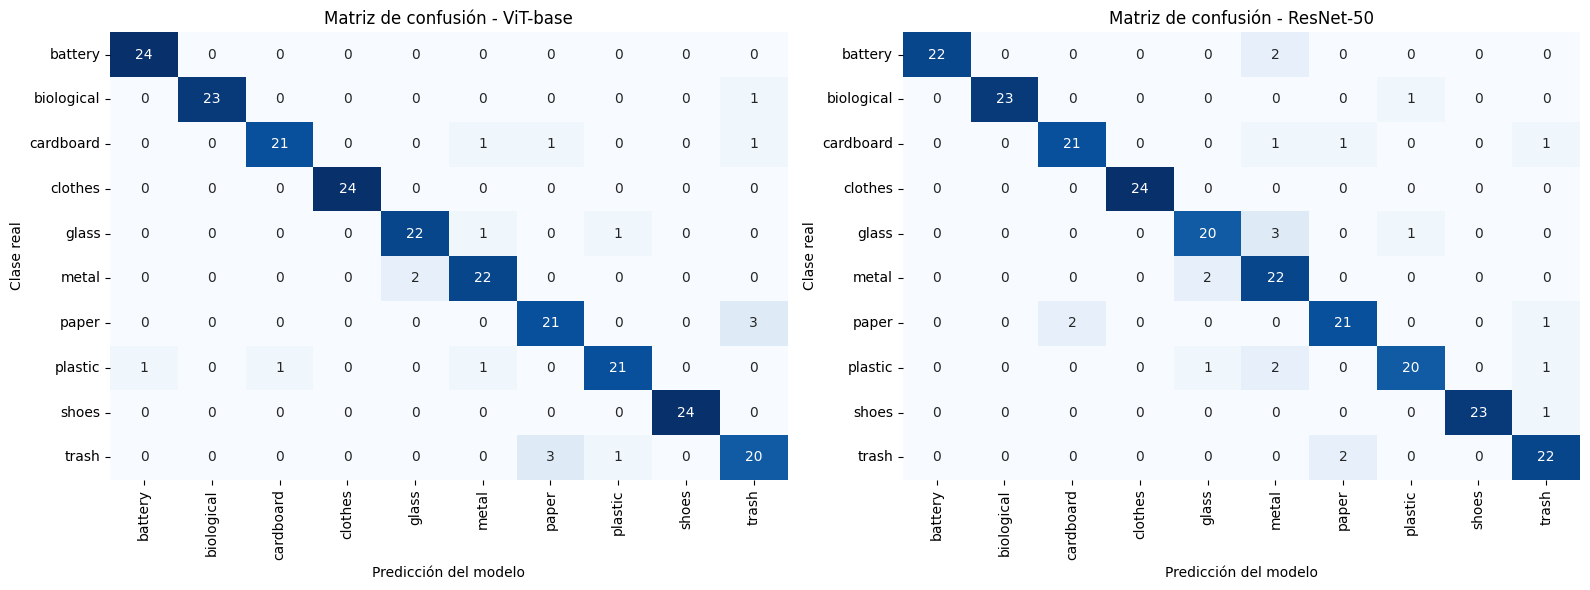

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, nombre in zip(axes, predicciones):
    cm = confusion_matrix(y_test, predicciones[nombre])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes_names,
                yticklabels=classes_names, ax=ax, cbar=False)
    ax.set_title(f"Matriz de confusión - {nombre}")
    ax.set_xlabel("Predicción del modelo")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

Errores de ViT: 18 de 240


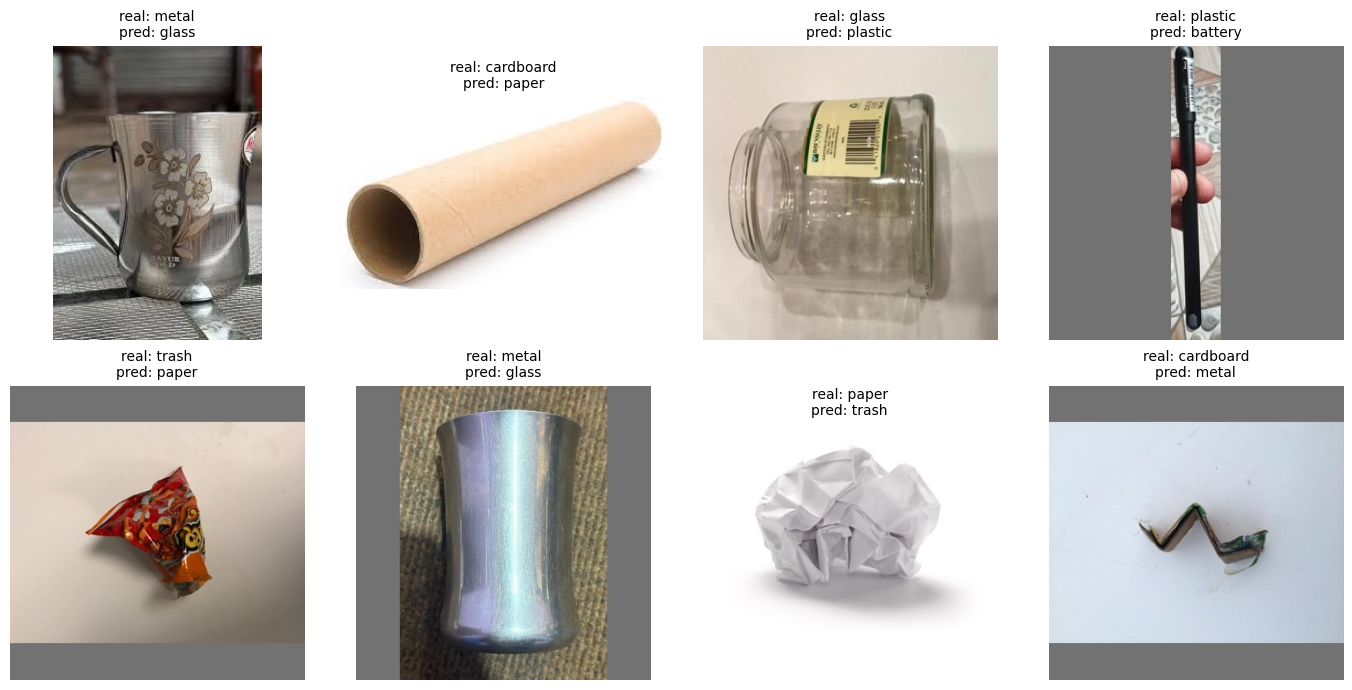

In [ ]:
# Veamos algunas imágenes mal clasificadas por ViT
errores = np.where(predicciones["ViT-base"] != y_test)[0]
print(f"Errores de ViT: {len(errores)} de {len(y_test)}")
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.ravel(), errores[:8]):
    ax.imshow(Image.open(test['path'].iloc[idx]).convert('RGB'))
    ax.set_title(f"real: {classes_names[y_test[idx]]}\npred: {classes_names[predicciones['ViT-base'][idx]]}", fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

### **5. Detección, segmentación y modelos generativos**

#### **5.1. Detección de objetos con un transformer (DETR)**

**DETR** (*DEtection TRansformer*) trata la detección como un problema de *predicción de conjuntos*: un Transformer recibe la imagen y un conjunto fijo de *object queries*, y cada query produce una caja y una clase. Usamos `facebook/detr-resnet-50`, preentrenado en **COCO** (80 categorías de objetos cotidianos).

config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

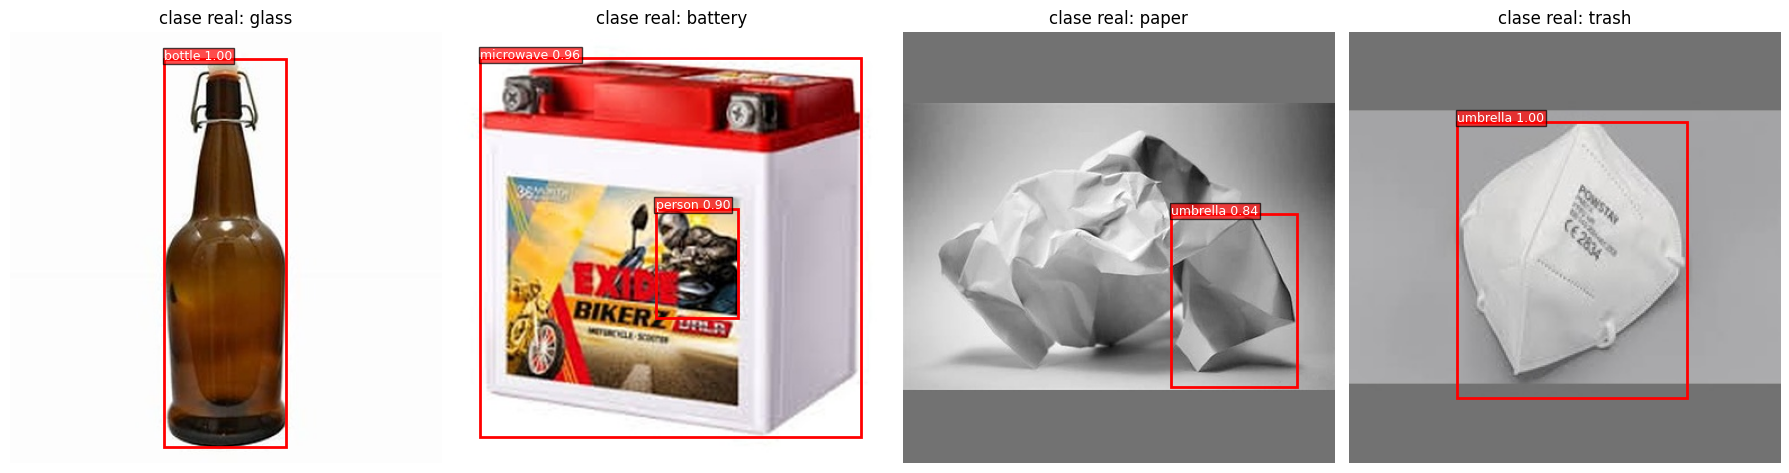

In [ ]:
dev_pipe = 0 if torch.cuda.is_available() else -1
detector = pipeline("object-detection", model="facebook/detr-resnet-50", device=dev_pipe)

imagenes_demo = test.sample(4, random_state=SEED)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (_, fila) in zip(axes, imagenes_demo.iterrows()):
    img = Image.open(fila['path']).convert('RGB')
    ax.imshow(img)
    for det in detector(img, threshold=0.5):
        b = det['box']
        ax.add_patch(patches.Rectangle((b['xmin'], b['ymin']), b['xmax'] - b['xmin'], b['ymax'] - b['ymin'],
                                       fill=False, edgecolor='red', linewidth=2))
        ax.text(b['xmin'], b['ymin'], f"{det['label']} {det['score']:.2f}", color='white',
                bbox=dict(facecolor='red', alpha=0.7, pad=1), fontsize=9)
    ax.set_title(f"clase real: {fila['label']}")
    ax.axis('off')
plt.tight_layout()
plt.show()

#### **5.2. Segmentación semántica con un Transfomer (SegFormer)**

La segmentación asigna una **clase a cada píxel**. **SegFormer** usa un *encoder* Transformer jerárquico (sin embeddings posicionales fijos) y una cabeza ligera que combina las escalas. Usamos `nvidia/segformer-b0-finetuned-ade-512-512`, preentrenado en **ADE20K** (150 categorías de escenas: pared, piso, persona, mesa, etc.).

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

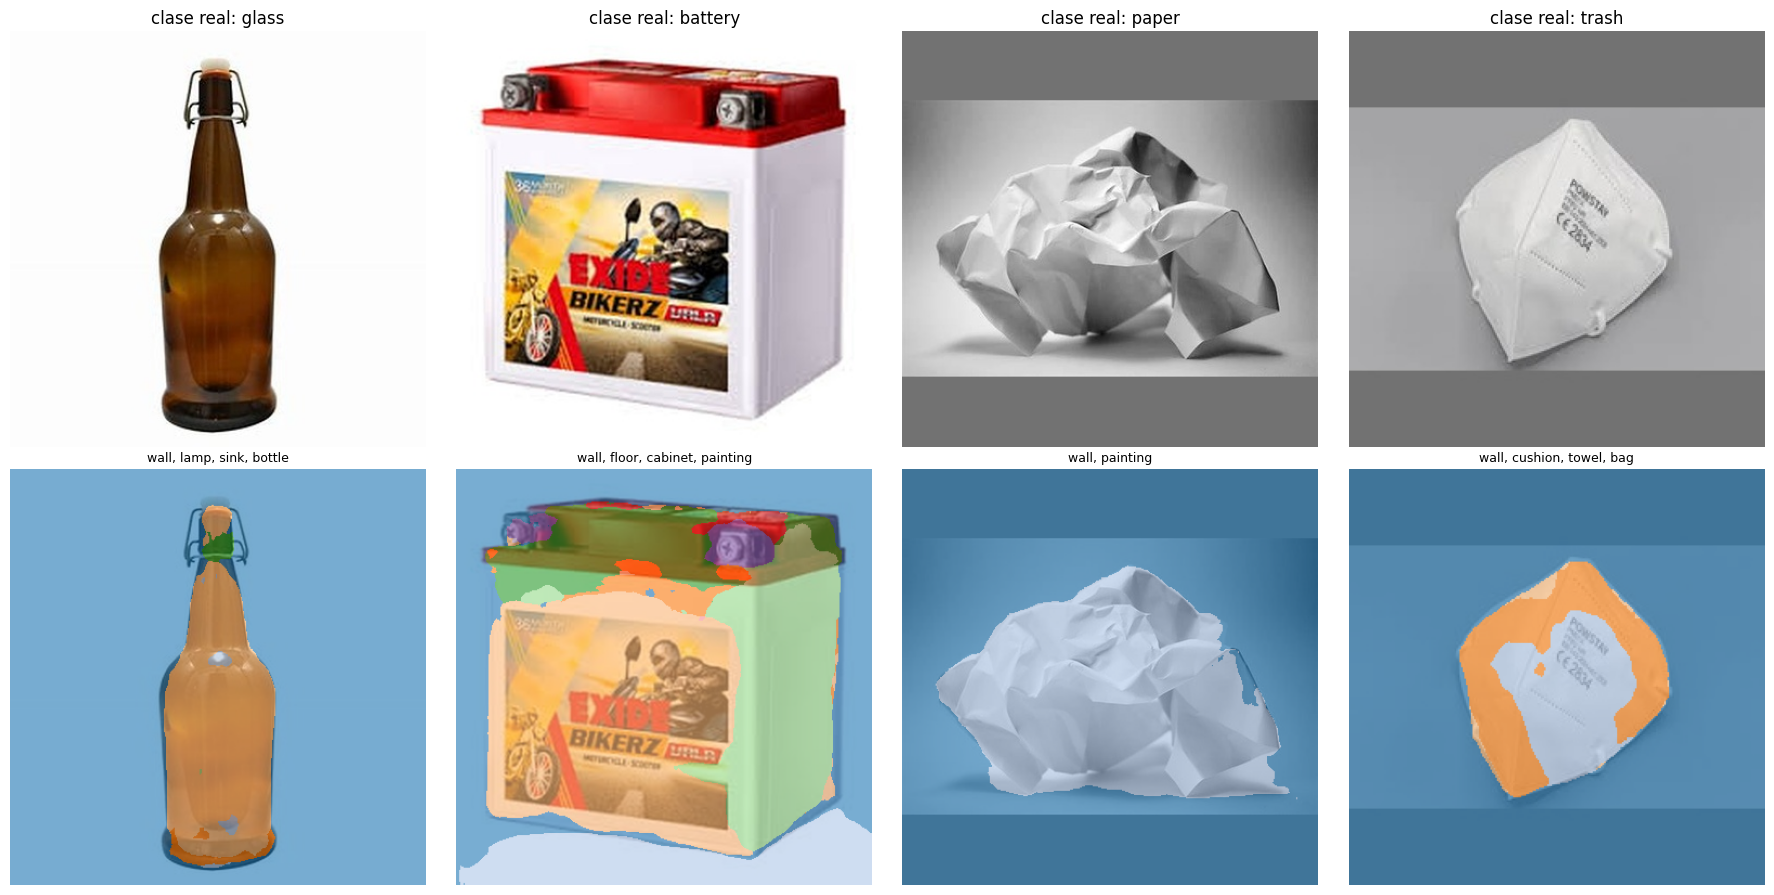

In [ ]:
segmentador = pipeline("image-segmentation", model="nvidia/segformer-b0-finetuned-ade-512-512", device=dev_pipe)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for j, (_, fila) in enumerate(imagenes_demo.iterrows()):
    img = Image.open(fila['path']).convert('RGB')
    base = np.array(img).astype(float)
    overlay = base.copy()
    cmap = plt.get_cmap('tab20')
    etiquetas = []
    for s, seg in enumerate(segmentador(img)):
        mascara = np.array(seg['mask'].resize(img.size)) > 0
        color = np.array(cmap(s % 20)[:3]) * 255
        overlay[mascara] = 0.4 * base[mascara] + 0.6 * color
        etiquetas.append(seg['label'])
    axes[0, j].imshow(img); axes[0, j].set_title(f"clase real: {fila['label']}"); axes[0, j].axis('off')
    axes[1, j].imshow(overlay.astype(np.uint8)); axes[1, j].axis('off')
    axes[1, j].set_title(", ".join(etiquetas[:4]), fontsize=9)
plt.tight_layout()
plt.show()

**Cerremos con unas conclusiones:**

1. Un ViT no tiene el sesgo inductivo de las convoluciones (localidad, invariancia a traslación): por eso depende mucho del **preentrenamiento a gran escala**. Aquí funciona bien con pocas imágenes porque reutilizamos lo que aprendió en ImageNet-21k.
2. El mapa de atención del `[CLS]` muestra a dónde mira el modelo, no por qué decide. Es la misma advertencia de nuestro lab7 con BertViz.
3. DETR y SegFormer están entrenados con otros datos y otras categorías (COCO, ADE20K). Que "funcionen" en general no significa que sirvan para nuestras clases sin adaptarlos.

### **6. Preguntas**

1. **ViT vs. CNN.** Compara ViT-base y ResNet-50 en accuracy, macro-F1, recall de la peor clase, número de parámetros y tiempo de extracción. ¿Cuál rinde mejor y por qué podría ser? Revisa las matrices de confusión y las imágenes mal clasificadas: ¿qué clases se confunden y por qué? Propón una modificación (por ejemplo, otro valor de `C`, aumento de datos, más imágenes por clase, concatenar los embeddings de ambos modelos), aplícala y compara el macro-F1 y el recall de la peor clase.

2. **Fine-tuning.** Descongela el ViT (o solo sus últimos bloques) y entrénalo con una tasa de aprendizaje baja (por ejemplo, 2e-5) y pocas épocas, agregando una capa de clasificación sobre el `[CLS]`. Compara con el modelo congelado con base en número de parámetros entrenables, tiempo por época, macro-F1 y recall de la peor clase. ¿Justifica la mejora el costo adicional?